# OpenPowerlifting — Prédire le total réalisé (`TotalKg`)
Régression (cible continue en kg), évaluée avec la RMSE.

Résumé : nouvelles variables, validation croisée pour **comparer** plusieurs méthodes (régression linéaire, Ridge, forêt aléatoire, gradient boosting) et choix des hyper-paramètres par validation croisée.

Attention : pour faire tourner le code, il faut uploader train.csv et test.csv dans les fichiers.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Mode test rapide : mettre par exemple 15000 pour n'utiliser qu'un sous-échantillon du train
# (None = tout le train). Les résultats du rapport correspondent à None.
ECHANTILLON = 15000
SEED = 42

#### 1) Chargement des données

In [ ]:
# Chargement des données
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
if ECHANTILLON is not None:
    train = train.sample(ECHANTILLON, random_state=SEED).reset_index(drop=True)

In [ ]:
# Affichage des 5 premières lignes
train.head()

,id,Age,BodyweightKg,MeetYear,Sex,Equipment,AgeClass,BirthYearClass,WeightClassKg,Tested,Country,State,Federation,ParentFederation,MeetCountry,MeetState,Sanctioned,TotalKg
0,8624,25.0,86.90,2018,M,Wraps,24-34,24-39,90,Untested,Chile,Unknown,ACHIPO,GPA,Chile,Unknown,Yes,662.5
1,109652,32.0,74.80,1989,M,Single-ply,24-34,24-39,75,Yes,Germany,Unknown,BVDG,IPF,West Germany,Unknown,Yes,570.0
2,43892,45.0,88.77,2014,M,Raw,45-49,40-49,90,Untested,USA,CA,USPA,IPL,USA,CA,Yes,577.5
3,18852,21.5,86.80,2023,M,Raw,20-23,19-23,93,Yes,Colombia,Unknown,FCLP,IPF,Colombia,Unknown,Yes,412.5
4,76556,19.5,94.20,2024,M,Raw,20-23,19-23,100,Yes,USA,CA,USAPL,Unknown,USA,CA,Yes,650.0


In [ ]:
# Taille des tableaux et statistiques de la variable à prédire
print(train.shape, test.shape)
train["TotalKg"].describe()

(15000, 18) (45000, 17)


,TotalKg
count,15000.000000
mean,494.989206
std,172.494728
min,65.000000
25%,352.500000
50%,497.500000
75%,615.000000
max,1202.500000


In [ ]:
# Valeurs manquantes (seulement les colonnes qui en ont)
nb_na = train.isnull().sum()
nb_na[nb_na > 0]

,0


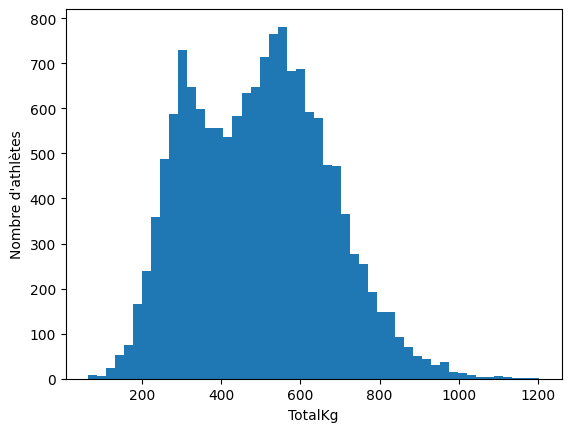

           mean         std  count
Sex                               
F    321.274003   83.238465   4587
M    571.537096  143.720756  10412
Mx   310.000000         NaN      1
                  mean         std  count
Equipment                                
Multi-ply   667.637215  205.490487    377
Raw         470.508632  157.942410   9337
Single-ply  528.799690  184.550052   3385
Unlimited   442.392956  162.793273    159
Wraps       527.940488  177.802876   1742


In [ ]:
# Distribution de la cible, et moyenne selon le sexe et l'équipement
plt.hist(train["TotalKg"], bins=50)
plt.xlabel("TotalKg")
plt.ylabel("Nombre d'athlètes")
plt.show()
print(train.groupby("Sex")["TotalKg"].agg(["mean", "std", "count"]))
print(train.groupby("Equipment")["TotalKg"].agg(["mean", "std", "count"]))

#### 2) Séparer les covariables de la variable à prédire

In [ ]:
# Covariables = toutes les colonnes sauf l'identifiant et la target 'TotalKg'
X = train.drop(columns=["id", "TotalKg"])
# Variable à prédire : colonne 'TotalKg'
Y = train["TotalKg"]
# Covariables du fichier test (sur lequel on devra prédire)
X_soumission = test.drop(columns=["id"])
n = len(X)

#### 3) Pré-traitements
+ **Regroupement des modalités rares** : une modalité vue moins de 100 fois dans le train devient "Autre" (`Federation` a près de 400 modalités).
+ **Nouvelles variables** : limite de la catégorie de poids (`WeightLimit`, `IsPlus`), écart au poids limite (`BW_margin`), termes quadratiques et interactions avec le sexe.
+ **Deux représentations** : one-hot pour les modèles linéaires (avec imputation par la médiane et normalisation, placées dans un `Pipeline` pour qu'elles soient réajustées à chaque pli de la validation croisée) ; encodage ordinal pour les modèles à base d'arbres.

In [ ]:
# 3.1) Regroupement des modalités rares (seuil calculé sur le train)
colonnes_texte = X.select_dtypes(exclude="number").columns.tolist()
for col in colonnes_texte:
    freq = X[col].value_counts()
    frequentes = freq[freq >= 100].index
    X[col] = X[col].where(X[col].isin(frequentes), "Autre")
    X_soumission[col] = X_soumission[col].where(X_soumission[col].isin(frequentes), "Autre")
print(len(colonnes_texte), "colonnes texte :", colonnes_texte)

13 colonnes texte : ['Sex', 'Equipment', 'AgeClass', 'BirthYearClass', 'WeightClassKg', 'Tested', 'Country', 'State', 'Federation', 'ParentFederation', 'MeetCountry', 'MeetState', 'Sanctioned']


In [ ]:
# 3.2) Nouvelles variables
def ajouter_variables(D):
    D = D.copy()
    classe = D["WeightClassKg"]
    D["IsPlus"] = classe.str.endswith("+").astype(float)                # catégorie "84+" -> 1
    D["WeightLimit"] = pd.to_numeric(classe.str.replace("+", "", regex=False), errors="coerce")  # limite en kg (NaN si inconnue)
    D["LimitMissing"] = D["WeightLimit"].isna().astype(float)
    D["BW_margin"] = D["BodyweightKg"] - D["WeightLimit"]               # écart au poids limite
    D["Age2"] = D["Age"] ** 2
    D["BW2"] = D["BodyweightKg"] ** 2
    D["logBW"] = np.log(D["BodyweightKg"])
    homme = (D["Sex"] == "M").astype(float)
    D["M_x_BW"] = homme * D["BodyweightKg"]                              # interactions avec le sexe
    D["M_x_Age"] = homme * D["Age"]
    D["M_x_Age2"] = homme * D["Age2"]
    return D

nouvelles = ["IsPlus", "WeightLimit", "LimitMissing", "BW_margin", "Age2", "BW2", "logBW", "M_x_BW", "M_x_Age", "M_x_Age2"]
# On traite train et test ensemble pour avoir exactement les mêmes colonnes
tout = ajouter_variables(pd.concat([X, X_soumission], ignore_index=True))

In [ ]:
# 3.3) Représentation pour les modèles linéaires : one-hot
Xl = pd.get_dummies(tout, dtype="float32")
cols_v1 = [c for c in Xl.columns if c not in nouvelles]       # version 1 = sans les nouvelles variables
Xl_train, Xl_test = Xl.iloc[:n], Xl.iloc[n:]
print("Variables (one-hot) : v1 =", len(cols_v1), "| v2 =", Xl.shape[1])

Variables (one-hot) : v1 = 211 | v2 = 221


In [ ]:
# 3.4) Représentation pour les arbres : encodage ordinal des colonnes texte
from sklearn.preprocessing import OrdinalEncoder
Xa = tout.copy()
Xa[colonnes_texte] = OrdinalEncoder().fit_transform(Xa[colonnes_texte])
masque_cat = [c in colonnes_texte for c in Xa.columns]
Xa_train, Xa_test = Xa.iloc[:n], Xa.iloc[n:]
Xa_rf_train, Xa_rf_test = Xa_train.fillna(-1), Xa_test.fillna(-1)   # la forêt aléatoire n'accepte pas les NaN
print("Variables (arbres) :", Xa.shape[1])

Variables (arbres) : 26


#### 4) Cadre de validation
Pour comparer les méthodes de façon équitable, chaque méthode est évaluée avec **la même validation croisée à 5 plis** (`cross_val_predict` : chaque athlète est prédit par un modèle qui ne l'a pas vu). Les hyper-paramètres sont choisis avec une validation croisée à 3 plis (plus rapide), puis le modèle retenu est évalué à 5 plis.

In [ ]:
from sklearn.model_selection import KFold, cross_val_predict, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import mean_squared_error

cv5 = KFold(5, shuffle=True, random_state=SEED)
cv3 = KFold(3, shuffle=True, random_state=SEED)

def rmse(y_vrai, y_pred):
    return np.sqrt(mean_squared_error(y_vrai, y_pred))

resultats, oof = {}, {}      # RMSE et prédictions "honnêtes" de chaque méthode

def evaluer(nom, modele, Xm):
    oof[nom] = cross_val_predict(modele, Xm, Y, cv=cv5)
    resultats[nom] = rmse(Y, oof[nom])
    print(f"{nom:<20} RMSE (5 plis) : {resultats[nom]:.2f} kg")

#### 5) Les méthodes d'apprentissage

##### 5.1) Référence : prédire toujours la moyenne

In [ ]:
from sklearn.dummy import DummyRegressor
evaluer("Moyenne", DummyRegressor(strategy="mean"), Xl_train[cols_v1])

Moyenne              RMSE (5 plis) : 172.49 kg


##### 5.2) Régression linéaire (OLS) : version 1 vs version 2 (nouvelles variables)

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge

def pipeline_lineaire(modele):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), modele)

evaluer("OLS (v1)", pipeline_lineaire(LinearRegression()), Xl_train[cols_v1])
evaluer("OLS (v2)", pipeline_lineaire(LinearRegression()), Xl_train)

OLS (v1)             RMSE (5 plis) : 87.83 kg
OLS (v2)             RMSE (5 plis) : 85.18 kg


##### 5.3) Régression Ridge — choix de la pénalisation alpha par validation croisée

In [ ]:
alphas = [0.1, 1, 10, 100, 1000, 10000]
recherche_ridge = GridSearchCV(pipeline_lineaire(Ridge()), {"ridge__alpha": alphas}, cv=cv3,
                               scoring="neg_root_mean_squared_error")
recherche_ridge.fit(Xl_train, Y)
tableau_ridge = pd.DataFrame({"alpha": alphas, "RMSE (3 plis)": -recherche_ridge.cv_results_["mean_test_score"]})
print(tableau_ridge)
print("alpha retenu :", recherche_ridge.best_params_["ridge__alpha"])

     alpha  RMSE (3 plis)
0      0.1      85.252901
1      1.0      85.251431
2     10.0      85.321266
3    100.0      85.891720
4   1000.0      87.027413
5  10000.0      92.610661
alpha retenu : 1


In [ ]:
evaluer("Ridge", recherche_ridge.best_estimator_, Xl_train)

Ridge                RMSE (5 plis) : 85.19 kg


##### 5.4) Forêt aléatoire — choix de `min_samples_leaf` et `max_features`
La grille est explorée sur un sous-échantillon de 30 000 lignes (pour aller plus vite), puis la forêt retenue est entraînée avec 100 arbres sur tout le train.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

taille = min(30000, n)
idx = np.random.RandomState(SEED).choice(n, taille, replace=False)
Xs, Ys = Xa_rf_train.iloc[idx], Y.iloc[idx]

lignes = []
for msl in [2, 5, 15]:
    for mf in [0.33, 0.7]:
        rf = RandomForestRegressor(n_estimators=40, min_samples_leaf=msl, max_features=mf, n_jobs=-1, random_state=SEED)
        p = cross_val_predict(rf, Xs, Ys, cv=cv3)
        lignes.append({"min_samples_leaf": msl, "max_features": mf, "RMSE (3 plis)": rmse(Ys, p)})
grille_rf = pd.DataFrame(lignes)
print(grille_rf)
meilleur_rf = grille_rf.loc[grille_rf["RMSE (3 plis)"].idxmin()]
print("retenu :", int(meilleur_rf["min_samples_leaf"]), meilleur_rf["max_features"])

   min_samples_leaf  max_features  RMSE (3 plis)
0                 2          0.33      88.052742
1                 2          0.70      87.981295
2                 5          0.33      87.469733
3                 5          0.70      87.033470
4                15          0.33      87.660769
5                15          0.70      87.262342
retenu : 5 0.7


In [ ]:
modele_rf = RandomForestRegressor(n_estimators=100, min_samples_leaf=int(meilleur_rf["min_samples_leaf"]),
                                  max_features=float(meilleur_rf["max_features"]), n_jobs=-1, random_state=SEED)
evaluer("Forêt aléatoire", modele_rf, Xa_rf_train)

Forêt aléatoire      RMSE (5 plis) : 86.26 kg


##### 5.5) Gradient boosting (`HistGradientBoostingRegressor`) — recherche aléatoire d'hyper-paramètres
10 combinaisons tirées au hasard dans la grille ci-dessous, chacune évaluée en validation croisée à 3 plis. Le nombre d'arbres est choisi automatiquement par arrêt précoce (`early_stopping`).

In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor

def hgb(**params):
    return HistGradientBoostingRegressor(categorical_features=masque_cat, max_iter=1000, early_stopping=True,
                                         validation_fraction=0.1, n_iter_no_change=20, random_state=SEED, **params)

espace = {"learning_rate": [0.03, 0.06, 0.1],
          "max_leaf_nodes": [15, 31, 63, 127],
          "min_samples_leaf": [20, 50, 100],
          "l2_regularization": [0, 1, 10]}
recherche_hgb = RandomizedSearchCV(hgb(), espace, n_iter=10, cv=cv3, scoring="neg_root_mean_squared_error",
                                   random_state=SEED)
recherche_hgb.fit(Xa_train, Y)
tableau_hgb = pd.DataFrame(recherche_hgb.cv_results_["params"])
tableau_hgb["RMSE (3 plis)"] = -recherche_hgb.cv_results_["mean_test_score"]
print(tableau_hgb.sort_values("RMSE (3 plis)").to_string(index=False))
print("retenu :", recherche_hgb.best_params_)

 min_samples_leaf  max_leaf_nodes  learning_rate  l2_regularization  RMSE (3 plis)
              100              15           0.10                  1      83.108943
              100              31           0.03                 10      83.189652
               50              31           0.03                  0      83.254989
              100             127           0.03                 10      83.496679
              100             127           0.06                 10      83.685786
              100             127           0.03                  0      83.690367
               20              63           0.10                  0      84.077093
               50              63           0.10                  1      84.138005
               50             127           0.03                  0      84.145722
               20             127           0.03                  1      84.457365
retenu : {'min_samples_leaf': 100, 'max_leaf_nodes': 15, 'learning_rate': 0.1, 'l2_regu

In [ ]:
evaluer("Gradient boosting", hgb(**recherche_hgb.best_params_), Xa_train)

Gradient boosting    RMSE (5 plis) : 82.81 kg


#### 6) Comparaison des méthodes

Gradient boosting     82.81
OLS (v2)              85.18
Ridge                 85.19
Forêt aléatoire       86.26
OLS (v1)              87.83
Moyenne              172.49
dtype: float64


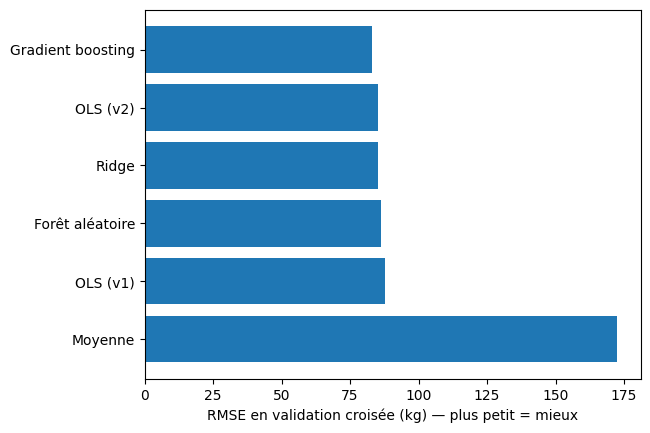

In [ ]:
comparaison = pd.Series(resultats).sort_values()
print(comparaison.round(2))

plt.barh(comparaison.index[::-1], comparaison.values[::-1])
plt.xlabel("RMSE en validation croisée (kg) — plus petit = mieux")
plt.show()

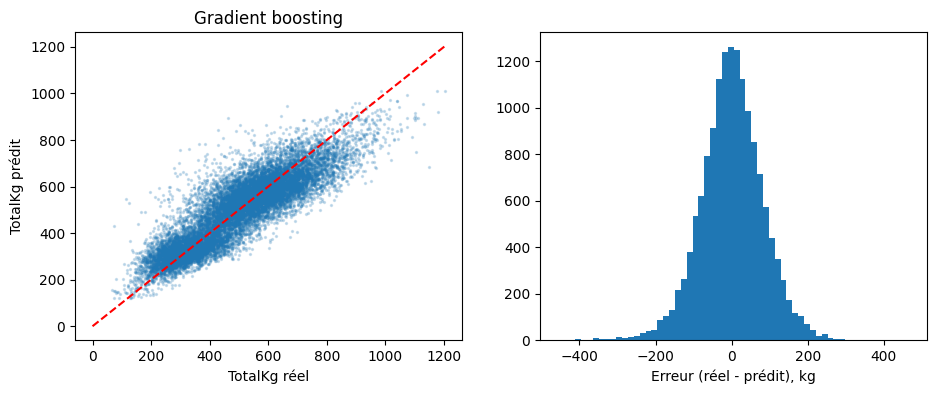

In [ ]:
# Prédictions vs valeurs réelles pour le meilleur modèle, et distribution des erreurs
meilleur = comparaison.index[0]
erreurs = Y - oof[meilleur]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(Y, oof[meilleur], s=2, alpha=0.2)
axes[0].plot([0, Y.max()], [0, Y.max()], color="red", linestyle="--")
axes[0].set_xlabel("TotalKg réel"); axes[0].set_ylabel("TotalKg prédit"); axes[0].set_title(meilleur)
axes[1].hist(erreurs, bins=60)
axes[1].set_xlabel("Erreur (réel - prédit), kg")
plt.show()

In [ ]:
# Erreur du meilleur modèle selon le sexe et l'équipement
for var in ["Sex", "Equipment"]:
    print(erreurs.groupby(X[var]).agg(lambda e: np.sqrt((e ** 2).mean())).round(1).rename("RMSE"))

Sex
Autre    66.7
F        63.0
M        90.2
Name: RMSE, dtype: float64
Equipment
Multi-ply     110.7
Raw            76.9
Single-ply     89.3
Unlimited      96.9
Wraps          91.5
Name: RMSE, dtype: float64


##### Variables les plus importantes (importance par permutation)
On entraîne le modèle retenu sur 80 % du train et on mesure, sur les 20 % restants, de combien la RMSE augmente quand on mélange aléatoirement les valeurs d'une variable.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance

Xtr, Xva, ytr, yva = train_test_split(Xa_train, Y, test_size=0.2, random_state=SEED)
m = hgb(**recherche_hgb.best_params_).fit(Xtr, ytr)
print("RMSE hold-out 20 % :", round(rmse(yva, m.predict(Xva)), 2))
pi = permutation_importance(m, Xva, yva, scoring="neg_root_mean_squared_error", n_repeats=3, random_state=SEED)
importances = pd.Series(pi.importances_mean, index=Xa_train.columns).sort_values(ascending=False)
print(importances.head(10).round(1))

RMSE hold-out 20 % : 82.31
M_x_BW            63.0
BodyweightKg      16.3
M_x_Age           15.0
Equipment         13.4
AgeClass          12.1
Federation         3.3
BW_margin          1.5
MeetYear           1.3
Tested             1.2
BirthYearClass     0.6
dtype: float64


##### Un mélange de modèles apporte-t-il quelque chose ?
On cherche les poids positifs $w_k$ qui minimisent l'erreur du mélange des prédictions "honnêtes" (`nnls`).

In [ ]:
from scipy.optimize import nnls
noms = ["Ridge", "Forêt aléatoire", "Gradient boosting"]
O = np.column_stack([oof[k] for k in noms])
poids, _ = nnls(O, Y.values)
print(dict(zip(noms, poids.round(3))))
print("RMSE du mélange :", round(rmse(Y, O @ poids), 2), "| gradient boosting seul :", round(resultats["Gradient boosting"], 2))

{'Ridge': np.float64(0.248), 'Forêt aléatoire': np.float64(0.147), 'Gradient boosting': np.float64(0.606)}
RMSE du mélange : 82.27 | gradient boosting seul : 82.81


#### 7) Modèle final et création de la soumission
Le gradient boosting est le plus précis en validation croisée ; le mélange n'apporte qu'un gain négligeable, on garde donc le modèle seul (plus simple). Il est réentraîné sur **tout** le train.

In [ ]:
modele_final = hgb(**recherche_hgb.best_params_)
modele_final.fit(Xa_train, Y)
print("nombre d'arbres :", modele_final.n_iter_)
pred_soumission = modele_final.predict(Xa_test)

nombre d'arbres : 159


In [ ]:
soumission = pd.DataFrame({"id": test["id"], "TotalKg": pred_soumission})
soumission.to_csv("submission.csv", index=False)
soumission.head()

,id,TotalKg
0,59770,749.146033
1,21362,513.398094
2,127324,633.909545
3,140509,381.533452
4,144297,292.934896
